# Tema 3.3 · Indexado y recuperación de imágenes

**Algoritmos y Arquitecturas para Procesado de Imágenes** · Grado en Ciencia de Datos e IA

Una vez tenemos un vector por imagen, ¿cómo encontramos las más parecidas entre millones, y cómo medimos si lo hacemos bien?

1. Medidas de similitud y cuándo usar cada una.
2. La maldición de la dimensionalidad.
3. Búsqueda exacta: fuerza bruta frente a árbol k-d.
4. Evaluar un sistema de recuperación: P@k, AP y mAP.
5. Búsqueda aproximada: un índice IVF escrito desde cero.
6. **[Colab]** FAISS: IVF, PQ y HNSW en la práctica.
7. Hashing perceptual para detectar duplicados.

Las secciones 1–5 y 7 funcionan sin GPU ni descargas.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage import data, color, transform, feature, util

warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.precision', 3)

## 1. Medidas de similitud

| Medida | Fórmula | Úsala con |
|---|---|---|
| Euclídea | $\sqrt{\sum_i (x_i-y_i)^2}$ | vectores densos genéricos |
| Coseno | $\frac{x\cdot y}{\lVert x\rVert\,\lVert y\rVert}$ | embeddings (CNN, CLIP) |
| χ² | $\frac12\sum_i \frac{(h_i-g_i)^2}{h_i+g_i}$ | histogramas (color, LBP, BoVW) |
| Intersección | $\sum_i \min(h_i,g_i)$ | histogramas normalizados (similitud: más es mejor) |
| Hamming | $\sum_i [a_i \neq b_i]$ | códigos binarios (hashes, ORB) |

In [2]:
def l2(x, y): return np.sqrt(np.sum((x - y) ** 2))
def coseno(x, y): return x @ y / (np.linalg.norm(x) * np.linalg.norm(y))
def chi2(h, g, eps=1e-10): return 0.5 * np.sum((h - g) ** 2 / (h + g + eps))
def interseccion(h, g): return np.sum(np.minimum(h, g))
def hamming(a, b): return int(np.sum(a != b))

rng = np.random.default_rng(0)
x, y = rng.normal(size=128), rng.normal(size=128)
xn, yn = x / np.linalg.norm(x), y / np.linalg.norm(y)
print(f'Vectores normalizados: ‖x−y‖² = {l2(xn, yn) ** 2:.4f}   2 − 2·cos = {2 - 2 * coseno(xn, yn):.4f}')

h = np.array([0.5, 0.3, 0.2, 0.0]); g = np.array([0.4, 0.4, 0.1, 0.1])
print(f'Histogramas: χ² = {chi2(h, g):.3f}   intersección = {interseccion(h, g):.2f}   L2 = {l2(h, g):.3f}')
print('Hamming entre 10110 y 11100:', hamming(np.array([1, 0, 1, 1, 0]), np.array([1, 1, 1, 0, 0])))

Vectores normalizados: ‖x−y‖² = 1.9947   2 − 2·cos = 1.9947
Histogramas: χ² = 0.079   intersección = 0.80   L2 = 0.200
Hamming entre 10110 y 11100: 2

Con vectores normalizados, la distancia euclídea y el coseno dan **el mismo ranking** (‖x−y‖² = 2 − 2·cos). Por eso es habitual normalizar los embeddings y buscar con el producto escalar.

## 2. La maldición de la dimensionalidad

Generamos 1 000 puntos uniformes en $[0,1]^d$ y una consulta, y medimos el **contraste** $(d_{max}-d_{min})/d_{min}$ entre el vecino más lejano y el más cercano.

d=    2  contraste=   40.21
d=    8  contraste=    3.30
d=   32  contraste=    0.87
d=  128  contraste=    0.37
d=  512  contraste=    0.19
d= 2048  contraste=    0.08

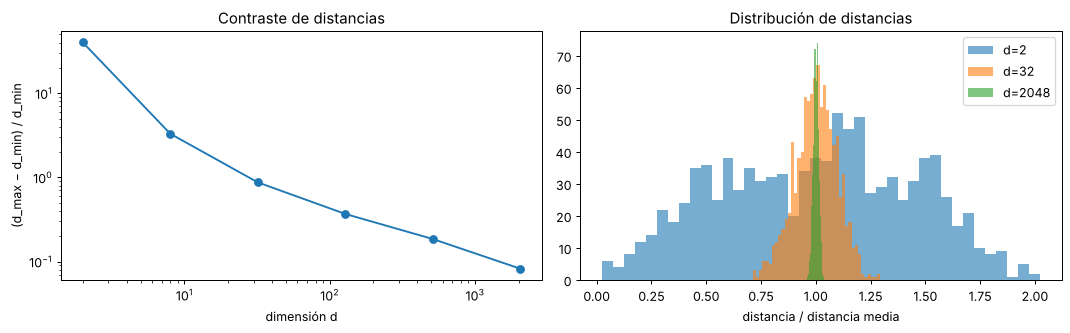

In [3]:
dims = [2, 8, 32, 128, 512, 2048]
contraste = []
for d in dims:
    P = rng.uniform(size=(1000, d)); q = rng.uniform(size=d)
    dist = np.linalg.norm(P - q, axis=1)
    contraste.append((dist.max() - dist.min()) / dist.min())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(dims, contraste, 'o-'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('dimensión d'); ax[0].set_ylabel('(d_max − d_min) / d_min'); ax[0].set_title('Contraste de distancias')
for d in [2, 32, 2048]:
    P = rng.uniform(size=(1000, d)); q = rng.uniform(size=d)
    dist = np.linalg.norm(P - q, axis=1)
    ax[1].hist(dist / dist.mean(), bins=40, alpha=0.6, label=f'd={d}')
ax[1].set_xlabel('distancia / distancia media'); ax[1].legend(); ax[1].set_title('Distribución de distancias')
plt.tight_layout(); plt.show()
for d, c in zip(dims, contraste):
    print(f'd={d:5d}  contraste={c:8.2f}')

En alta dimensión **todas las distancias se parecen**: el «vecino más cercano» apenas está más cerca que el resto. Los embeddings reales no son uniformes (viven cerca de superficies de menor dimensión) y se comportan mejor, pero las estructuras de búsqueda clásicas sufren.

## 3. Búsqueda exacta: fuerza bruta frente a árbol k-d

Un árbol k-d divide el espacio con cortes por coordenadas. Funciona muy bien en pocas dimensiones y se degrada al crecer d.

In [4]:
from sklearn.neighbors import NearestNeighbors

N, Q = 20000, 200
filas = []
for d in [2, 8, 32, 128]:
    X = rng.normal(size=(N, d)).astype(np.float32); Xq = rng.normal(size=(Q, d)).astype(np.float32)
    for alg in ['brute', 'kd_tree']:
        nn = NearestNeighbors(n_neighbors=10, algorithm=alg).fit(X)
        t0 = time.perf_counter(); nn.kneighbors(Xq); t = time.perf_counter() - t0
        filas.append([d, alg, 1000 * t / Q])
tiempos = pd.DataFrame(filas, columns=['d', 'algoritmo', 'ms por consulta']).pivot(index='d', columns='algoritmo')
display(tiempos)

ms por consulta        
algoritmo           brute kd_tree
d                                
2                   0.129   0.011
8                   0.050   0.176
32                  0.089   2.885
128                 0.132  12.581

> Los tiempos dependen de la máquina, pero la tendencia se repite: el árbol k-d gana con d pequeña y pierde su ventaja (o va más lento que la fuerza bruta) cuando la dimensión crece.

## 4. Evaluar la recuperación: P@k, AP y mAP

Primero comprobamos nuestra implementación con el ejemplo de las diapositivas: 10 resultados, relevantes en las posiciones 1, 3, 4 y 7, y **5 relevantes en total** en la colección.

In [5]:
def precision_at_k(rel, k):
    return np.mean(rel[:k])

def average_precision(rel, R):
    """rel: vector 0/1 del ranking; R: número total de relevantes en la colección."""
    rel = np.asarray(rel)
    pk = np.cumsum(rel) / np.arange(1, len(rel) + 1)
    return np.sum(pk * rel) / R

rel = np.array([1, 0, 1, 1, 0, 0, 1, 0, 0, 0])
print('P@k:', np.round(np.cumsum(rel) / np.arange(1, 11), 2))
print(f'AP = {average_precision(rel, R=5):.3f}   (se divide entre 5: una relevante no se recuperó)')

P@k: [1.   0.5  0.67 0.75 0.6  0.5  0.57 0.5  0.44 0.4 ]
AP = 0.598   (se divide entre 5: una relevante no se recuperó)

Ahora un sistema real: los 1 797 dígitos de `scikit-learn`. Cada imagen hace de consulta contra todas las demás (*leave-one-out*); son relevantes las del mismo dígito. Comparamos tres representaciones.

In [6]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score

digits = load_digits()
y = digits.target
reps = {
    'píxeles (64)': digits.data,
    'HOG (324)': np.array([feature.hog(transform.resize(im / 16, (32, 32)), orientations=9,
                                       pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for im in digits.images]),
}
reps['HOG + PCA (20)'] = PCA(20, random_state=0).fit_transform(reps['HOG (324)'])

def evaluar(F, y, k=10):
    F = F - F.mean(0)
    F = F / np.linalg.norm(F, axis=1, keepdims=True)
    S = F @ F.T
    np.fill_diagonal(S, -np.inf)                      # la consulta no se recupera a sí misma
    orden = np.argsort(-S, axis=1)
    rel = (y[orden] == y[:, None]).astype(int)[:, :-1]  # quitamos la propia consulta (última)
    R = np.bincount(y)[y] - 1
    p10 = rel[:, :k].mean(1)
    ap = np.array([average_precision(r, Ri) for r, Ri in zip(rel, R)])
    return p10.mean(), ap.mean(), orden, ap

res = {}
for nombre, F in reps.items():
    p10, mAP, orden, ap = evaluar(F, y)
    res[nombre] = {'P@10': p10, 'mAP': mAP}
display(pd.DataFrame(res).T)

# Comprobación con scikit-learn para la primera consulta
F = reps['HOG (324)']; F = F - F.mean(0); F = F / np.linalg.norm(F, axis=1, keepdims=True)
s = F @ F[0]; s[0] = -np.inf
mask = np.arange(len(y)) != 0
_, _, _, ap_hog = evaluar(reps['HOG (324)'], y)
print(f'AP consulta 0: nuestra = {ap_hog[0]:.4f}   sklearn = {average_precision_score(y[mask] == y[0], s[mask]):.4f}')

AP consulta 0: nuestra = 0.9957   sklearn = 0.9957

,P@10,mAP
píxeles (64),0.960,0.677
HOG (324),0.970,0.736
HOG + PCA (20),0.963,0.753


Veamos la consulta en la que HOG **más mejora** a los píxeles crudos en el top-10 (en verde los resultados correctos):

Consulta 170 · dígito 8

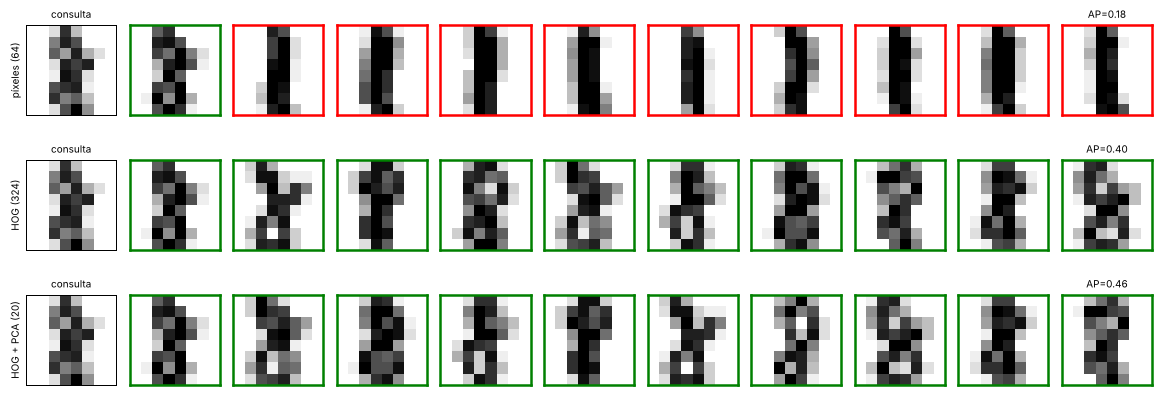

In [7]:
_, _, orden_pix, _ = evaluar(reps['píxeles (64)'], y)
_, _, orden_hog, _ = evaluar(reps['HOG (324)'], y)
err = lambda o: (y[o[:, :10]] != y[:, None]).sum(1)
q = int(np.argmax(err(orden_pix) - err(orden_hog)))
print('Consulta', q, '· dígito', y[q])
fig, axes = plt.subplots(len(reps), 11, figsize=(13, 1.4 * len(reps) + 0.6))
for r, (nombre, F) in enumerate(reps.items()):
    _, _, orden, ap = evaluar(F, y)
    axes[r, 0].imshow(digits.images[q], cmap='gray_r'); axes[r, 0].set_title('consulta', fontsize=8)
    axes[r, 0].set_ylabel(nombre, fontsize=8)
    for c, i in enumerate(orden[q, :10]):
        axes[r, c + 1].imshow(digits.images[i], cmap='gray_r')
        for sp in axes[r, c + 1].spines.values():
            sp.set_color('green' if y[i] == y[q] else 'red'); sp.set_linewidth(2)
    axes[r, 10].set_title(f'AP={ap[q]:.2f}', fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 5. Búsqueda aproximada: un índice IVF desde cero

**IVF** (*inverted file*): agrupamos la colección con k-means en `nlist` celdas. Para buscar, comparamos la consulta sólo con los vectores de las `nprobe` celdas más cercanas. Medimos el **recall@10** (qué fracción de los 10 vecinos exactos encontramos) frente a la velocidad.

100,000 vectores de 64 dimensiones en 256 celdas (≈390 por celda)

,nprobe,recall@10,aceleración ×
0,1,0.385,172.521
1,2,0.622,76.234
2,4,0.920,59.508
3,8,1.000,28.980
4,16,1.000,11.688
5,32,1.000,4.917


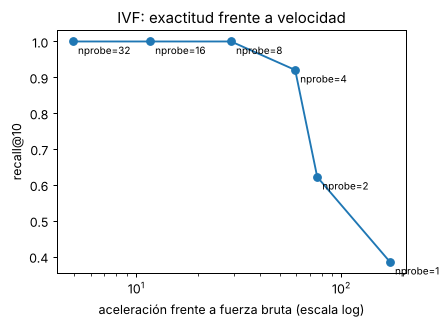

In [8]:
from sklearn.cluster import MiniBatchKMeans

d, N, Q, nlist = 64, 100_000, 200, 256
centros = rng.normal(size=(50, d)) * 3
X = (centros[rng.integers(0, 50, N)] + rng.normal(size=(N, d))).astype(np.float32)
Xq = (centros[rng.integers(0, 50, Q)] + rng.normal(size=(Q, d))).astype(np.float32)

def top10_bruto(q):
    return np.argpartition(((X - q) ** 2).sum(1), 10)[:10]

t0 = time.perf_counter(); verdad = [set(top10_bruto(q)) for q in Xq]; t_bruto = (time.perf_counter() - t0) / Q

km = MiniBatchKMeans(nlist, random_state=0, n_init=3, batch_size=4096).fit(X)
asign = km.labels_
listas = [np.where(asign == c)[0] for c in range(nlist)]   # «listas invertidas»
print(f'{N:,} vectores de {d} dimensiones en {nlist} celdas (≈{N // nlist} por celda)')

def buscar_ivf(q, nprobe):
    celdas = np.argsort(((km.cluster_centers_ - q) ** 2).sum(1))[:nprobe]
    cand = np.concatenate([listas[c] for c in celdas])
    d2 = ((X[cand] - q) ** 2).sum(1)
    return cand[np.argsort(d2)[:10]]

filas = []
for nprobe in [1, 2, 4, 8, 16, 32]:
    t0 = time.perf_counter(); res_ivf = [buscar_ivf(q, nprobe) for q in Xq]; t = (time.perf_counter() - t0) / Q
    recall = np.mean([len(v & set(r)) / 10 for v, r in zip(verdad, res_ivf)])
    filas.append([nprobe, recall, t_bruto / t])
ivf = pd.DataFrame(filas, columns=['nprobe', 'recall@10', 'aceleración ×'])
display(ivf)

plt.figure(figsize=(5, 3.5))
plt.plot(ivf['aceleración ×'], ivf['recall@10'], 'o-')
for _, f in ivf.iterrows():
    plt.annotate(f"nprobe={int(f['nprobe'])}", (f['aceleración ×'], f['recall@10']), fontsize=8, xytext=(4, -10), textcoords='offset points')
plt.xscale('log'); plt.xlabel('aceleración frente a fuerza bruta (escala log)'); plt.ylabel('recall@10'); plt.title('IVF: exactitud frente a velocidad'); plt.show()

## 6. [Colab] FAISS en la práctica

FAISS (Meta) implementa estos índices en C++ y es lo que se usa en sistemas reales. Comparamos, sobre los mismos datos, la búsqueda exacta, IVF, IVF con cuantización de producto (PQ: cada vector se guarda en 8 bytes) y HNSW (grafo jerárquico).

In [ ]:
# [Colab] Instalar FAISS (sólo la primera vez)
!pip install -q faiss-cpu

In [ ]:
# [Colab] Comparar índices de FAISS
import faiss

def medir(index, nombre, bytes_por_vector, nprobe=None):
    if nprobe is not None:
        index.nprobe = nprobe
    t0 = time.perf_counter(); _, I = index.search(Xq, 10); t = (time.perf_counter() - t0) / Q
    recall = np.mean([len(v & set(r)) / 10 for v, r in zip(verdad, I)])
    return [nombre, recall, 1000 * t, bytes_por_vector]

filas = []
flat = faiss.IndexFlatL2(d); flat.add(X)
filas.append(medir(flat, 'Exacto (Flat)', 4 * d))

quant = faiss.IndexFlatL2(d)
ivfflat = faiss.IndexIVFFlat(quant, d, nlist); ivfflat.train(X); ivfflat.add(X)
for npb in [1, 8, 32]:
    filas.append(medir(ivfflat, f'IVF nprobe={npb}', 4 * d, nprobe=npb))

quant2 = faiss.IndexFlatL2(d)
ivfpq = faiss.IndexIVFPQ(quant2, d, nlist, 8, 8); ivfpq.train(X); ivfpq.add(X)   # 8 subvectores × 8 bits
filas.append(medir(ivfpq, 'IVF-PQ nprobe=8', 8, nprobe=8))

hnsw = faiss.IndexHNSWFlat(d, 32); hnsw.add(X)
filas.append(medir(hnsw, 'HNSW (M=32)', 4 * d))

display(pd.DataFrame(filas, columns=['índice', 'recall@10', 'ms por consulta', 'bytes por vector']))

## 7. Hashing perceptual: encontrar duplicados

**dHash**: escalar a 9×8 en grises, comparar cada píxel con su vecino derecho → 64 bits. Dos imágenes son casi-duplicados si sus huellas están a poca distancia de Hamming.

Creamos una pequeña colección con 8 imágenes y 6 variantes de cada una (brillo, reducción, JPEG de baja calidad, recorte, giro de 5° y espejo) y comprobamos qué variantes «reconoce» el hash.

In [9]:
def dhash(im, s=8):
    g = color.rgb2gray(im) if im.ndim == 3 else util.img_as_float(im)
    g = transform.resize(g, (s, s + 1), anti_aliasing=True)
    return (g[:, 1:] > g[:, :-1]).ravel()

def jpeg(im, q=20):
    ok, buf = cv2.imencode('.jpg', cv2.cvtColor(im, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, q])
    return cv2.cvtColor(cv2.imdecode(buf, 1), cv2.COLOR_BGR2RGB)

def rgb(im):
    return np.stack([im] * 3, -1) if im.ndim == 2 else im[..., :3]

fuentes = {n: rgb(getattr(data, n)()) for n in ['astronaut', 'chelsea', 'coffee', 'rocket', 'camera', 'coins', 'moon', 'brick']}
variantes = {
    'brillo +30 %': lambda im: np.clip(im * 1.3, 0, 255).astype(np.uint8),
    'reducida 25 %': lambda im: util.img_as_ubyte(transform.resize(im, (im.shape[0] // 4, im.shape[1] // 4), anti_aliasing=True)),
    'JPEG q=20': jpeg,
    'recorte 10 %': lambda im: im[im.shape[0] // 10: -im.shape[0] // 10, im.shape[1] // 10: -im.shape[1] // 10],
    'giro 5°': lambda im: util.img_as_ubyte(transform.rotate(im, 5, mode='edge')),
    'espejo': lambda im: im[:, ::-1],
}
H0 = {n: dhash(im) for n, im in fuentes.items()}
tabla = pd.DataFrame({v: {n: hamming(H0[n], dhash(f(im))) for n, im in fuentes.items()} for v, f in variantes.items()})
display(tabla)

otras = [hamming(H0[a], H0[b]) for i, a in enumerate(fuentes) for b in list(fuentes)[i + 1:]]
print(f'Distancia entre imágenes DISTINTAS: mínimo {min(otras)}, media {np.mean(otras):.1f} (de 64 bits)')

Distancia entre imágenes DISTINTAS: mínimo 22, media 32.7 (de 64 bits)

,brillo +30 %,reducida 25 %,JPEG q=20,recorte 10 %,giro 5°,espejo
astronaut,1,0,0,24,8,30
chelsea,0,2,1,16,5,36
coffee,5,2,1,13,6,18
rocket,0,0,0,11,4,26
camera,2,0,0,14,4,44
coins,2,3,1,25,16,32
moon,0,0,0,6,5,14
brick,0,1,4,21,9,32


**Lectura.** Brillo, reducción y JPEG apenas cambian la huella: son casi-duplicados fáciles de detectar con un umbral de unos 10 bits. El recorte y el giro la alteran más, y el espejo la destruye (el hash compara píxeles de izquierda a derecha). Un uso muy práctico: **buscar duplicados en un dataset antes de separar entrenamiento y prueba**, para evitar fugas de datos.

In [ ]:
# [Colab] Comparar con la librería imagehash (aHash, pHash, dHash)
!pip install -q imagehash
import imagehash
from PIL import Image

filas = []
for nombre, f in variantes.items():
    for alg in ['average_hash', 'phash', 'dhash']:
        h = getattr(imagehash, alg)
        dist = [h(Image.fromarray(im)) - h(Image.fromarray(f(im))) for im in fuentes.values()]
        filas.append([nombre, alg, np.mean(dist)])
display(pd.DataFrame(filas, columns=['variante', 'hash', 'Hamming medio']).pivot(index='variante', columns='hash'))

## 8. Ejercicios

1. En la sección 4, añade la representación «HOG + PCA (5)» y «HOG + PCA (50)». ¿Cuántas dimensiones necesitas para no perder mAP?
2. Calcula el mAP de la sección 4 con distancia euclídea **sin** normalizar los vectores. ¿Cambia el resultado? ¿Por qué?
3. En el IVF de la sección 5, prueba `nlist` = 64 y 1024. ¿Cómo cambia la curva recall-velocidad?
4. Propón un umbral de Hamming para detectar duplicados con dHash y calcula su precisión y recall sobre la tabla de la sección 7. ¿Qué variantes se escapan?
5. Haz que el hash sea invariante al espejo (pista: calcula también el hash de la imagen volteada y quédate con la menor distancia).